In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
pd.set_option('display.max_rows',None)
from pathlib import Path

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dados_path = Path('data')
df_o = pd.read_excel(dados_path / 'survey_all_responses_ptbr.xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

#print(df.columns.tolist())

95


In [ ]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]
#df = df[~(df['Você costuma utilizar ferramentas de segurança automatizadas em seu dia a dia?'] == 'Não costumo utilizar')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

['Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software'
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
(83, 102)


In [ ]:
df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()]

,Carimbo de data/hora,"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",Qual é a sua idade?,Em qual estado do Brasil você mora atualmente?,Qual é o seu gênero?,Qual é o seu nível de educação formal concluída?,Qual seu modelo de trabalho?,Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,"Por favor, indique a senioridade da posição que ocupa.",Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,...,Em quais fases do ciclo de desenvolvimento de software você costuma utilizar as ferramentas de segurança automatizadas selecionadas na pergunta anterior? (Selecione todas as opções que se aplicam),Quais recomendações você daria para um desenvolvedor sobre a adoção de ferramentas de segurança para seus projetos?,Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam),Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam),"Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email.","Quais são as razões pelas quais você opta por não utilizar ferramentas automatizadas de segurança de software? Por favor, descreva brevemente sobre.",Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?,"Se você respondeu ""Sim"" ou ""Talvez"" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque ""Nenhuma"" se respondeu ""Não"".","Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email..1",Marque a imagem em que aparece um filhote de cachorro:


In [ ]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

df = df.drop(df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()].index, axis=0)

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

0
0


In [ ]:
df['Qual é o seu nível de educação formal concluída?'].unique()

array(['Mestrado', 'Estudante de Doutorado', 'Ensino Superior',
       'Doutorado', 'Especialização', 'Ensino Médio',
       'Estudante de Mestrado'], dtype=object)

In [ ]:
df.isna().sum()

,0
Carimbo de data/hora,0
"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",0
Qual é a sua idade?,0
Em qual estado do Brasil você mora atualmente?,0
Qual é o seu gênero?,0
Qual é o seu nível de educação formal concluída?,0
Qual seu modelo de trabalho?,0
Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,0
"Por favor, indique a senioridade da posição que ocupa.",0
Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,0


In [ ]:

df.shape

(83, 102)

In [ ]:
coluna_experiencia = "experiencia_direta"
coluna_experiencia = 'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'
coluna_anos_experiencia_dev = 'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'
coluna_anos_experiencia_seg = 'Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?'
coluna_nivel_educacao = 'Qual é o seu nível de educação formal concluída?'
coluna_senioridade = 'Por favor, indique a senioridade da posição que ocupa.'
coluna_especialistas = 'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?'
coluna_certificacao = 'Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?'

tem_experiencia = 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.'

resposta_especialistas = ["Cryptographer", "Penetration tester",
                          "DevOps engineer", "Privacy engineer", "Security engineer"]
resposta_nao_certificacao = ["Não possui nenhuma certificação"]

In [ ]:
df_exp_direta = df[df[coluna_experiencia] == tem_experiencia]
df_exp_indireta = df[df[coluna_experiencia] != tem_experiencia]

In [ ]:
nivel_educacao_map = {
    'Ensino Médio': 1,
    'Ensino Superior': 2,
    'Especialização': 3,
    'Estudante de Mestrado': 4,
    'Mestrado': 5,
    'Estudante de Doutorado': 6,
    'Doutorado': 7
}

senioridade_map = {
    'Estagiário': 1,
    'Júnior (até 5 anos)': 2,
    'Pleno (6 a 9 anos)': 3,
    'Sênior (10+ anos)': 4
}

anos_exp_dev_map = {
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 5 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

anos_exp_seg_map = {
    'Nenhuma': 0,
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 6 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}


def interacao_exp_direta_especialista(row):
    if row['especialista'] and row['experiencia_direta']:
        return 3
    elif row['experiencia_direta'] and not row['especialista']:
        return 2
    else:
        return 1


def relacao_exp_direta_especialista(row):
    return (row['especialista'] + row['experiencia_direta'])/2


df[coluna_anos_experiencia_dev] = df[coluna_anos_experiencia_dev].map(
    anos_exp_dev_map)

df[coluna_senioridade] = df[coluna_senioridade].map(senioridade_map)

df[coluna_anos_experiencia_seg] = df[coluna_anos_experiencia_seg].map(
    anos_exp_seg_map)

In [ ]:
df['especialista'] = df[coluna_especialistas].apply(
    lambda x: 1 if x in resposta_especialistas else 0)

df['experiencia_direta'] = df[coluna_experiencia].apply(
    lambda x: 1 if x == tem_experiencia else 0)

df['certificacao'] = df[coluna_certificacao].apply(
    lambda x: 0 if x in resposta_nao_certificacao else 1)

df['Qual é o seu nível de educação formal concluída?'] = df['Qual é o seu nível de educação formal concluída?'].map(
    nivel_educacao_map)

df['interacao_exp_direta_especialista'] = df.apply(
    interacao_exp_direta_especialista, axis=1)

df['relacao_exp_direta_especialista'] = df.apply(
    relacao_exp_direta_especialista, axis=1)

In [ ]:
nivel_educacao = df['Qual é o seu nível de educação formal concluída?']
anos_exp_dev = df['Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?']
anos_exp_seg = df['Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?']
senioridade = df['Por favor, indique a senioridade da posição que ocupa.']
interacao_exp_direta_especialista_col = df['interacao_exp_direta_especialista']
relacao_exp_direta_especialista_col = df['relacao_exp_direta_especialista']
certificacao = df['certificacao']

In [ ]:
df.shape

(83, 107)

**Q28**

In [ ]:
import re

# Definição das respostas diretas, indiretas, grandes e pequenas
resposta_direta = 1
resposta_indireta = 0

resposta_pequena = ["Até 9 funcionários",
                    "De 10 a 49 funcionários", "De 50 a 99 funcionários"]
resposta_grande = ["De 100 a 499 funcionários",
                   "De 500 a 999 funcionários", "Mais de 1000 funcionários"]

resposta_especialista = 1
resposta_nao_especialista = 0

# Nome das colunas corretas
coluna_experiencia = 'experiencia_direta'
coluna_tamanhoempresa = 'Qual o tamanho da empresa para a qual você trabalha atualmente?'
coluna_especialistas = 'especialista'
coluna_sistemas = 'Quais são os tipos de sistemas que você trabalha?'

# Filtra as respostas diretas e indiretas
diretas = df[df[coluna_experiencia] == resposta_direta].copy()
indiretas = df[df[coluna_experiencia] == resposta_indireta].copy()

# Filtra as respostas de empresas grandes e pequenas
grandes = df[df[coluna_tamanhoempresa].isin(resposta_grande)].copy()
pequenas = df[df[coluna_tamanhoempresa].isin(resposta_pequena)].copy()

especialistas = df[df[coluna_especialistas] == resposta_especialista].copy()
nao_especialistas = df[df[coluna_especialistas]
                       == resposta_nao_especialista].copy()

In [ ]:
print("Quantidade de participantes no grupo Experiência Direta:", len(diretas))
print("Quantidade de participantes no grupo Experiência Indireta:", len(indiretas))
print("--"*35)

print("Quantidade de participantes no grupo Big:", len(grandes))
print("Quantidade de participantes no grupo Small:", len(pequenas))
print("--"*35)

print("Quantidade de participantes no grupo Especialistas:", len(especialistas))
print("Quantidade de participantes no grupo Não Especialistas:",
      len(nao_especialistas))
print("--"*35)
print(f"Porcentagem de participantes no grupo Big: {len(grandes)/88:.1f}")
print(f"Porcentagem de participantes no grupo Small: {len(pequenas)/88:.1f}")

Quantidade de participantes no grupo Experiência Direta: 62
Quantidade de participantes no grupo Experiência Indireta: 21
----------------------------------------------------------------------
Quantidade de participantes no grupo Big: 65
Quantidade de participantes no grupo Small: 16
----------------------------------------------------------------------
Quantidade de participantes no grupo Especialistas: 26
Quantidade de participantes no grupo Não Especialistas: 57
----------------------------------------------------------------------
Porcentagem de participantes no grupo Big: 0.7
Porcentagem de participantes no grupo Small: 0.2


In [ ]:
col_desafios = "Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam)"


In [ ]:
desafios_opcoes = [
    'Custo',
    'Curva de aprendizado',
    'Integração com outras ferramentas',
    'Performance do sistema',
    'Falsos positivos',
    'Falsos negativos',
    'Manutenção das ferramentas automatizadas',
    'Escalabilidade',
    'Falta de suporte técnico',
    'Compatibilidade com diferentes ambientes de desenvolvimento',
    'Necessidade de atualizações frequentes',
    'Aderência a normas e compliance',
    'Falta de visibilidade ou relatórios inadequados',
    'Outros'

]

In [ ]:
def contar_respostas(df_grupo):
    contagem = {op: 0 for op in desafios_opcoes}

    for _, row in df_grupo.iterrows():
        resp = row[col_desafios]
        if pd.isna(resp):
            continue

        escolhas = [op.strip() for op in resp.split(",")]

        for op in escolhas:
            if op in contagem:
                contagem[op] += 1
            else:
                contagem["Outros"] += 1

    return pd.DataFrame.from_dict(contagem, orient="index", columns=["Total"])


In [ ]:
df_diretas = contar_respostas(diretas)
df_indiretas = contar_respostas(indiretas)

df_grandes = contar_respostas(grandes)
df_pequenas = contar_respostas(pequenas)

df_especialistas = contar_respostas(especialistas)
df_nao_especialistas = contar_respostas(nao_especialistas)


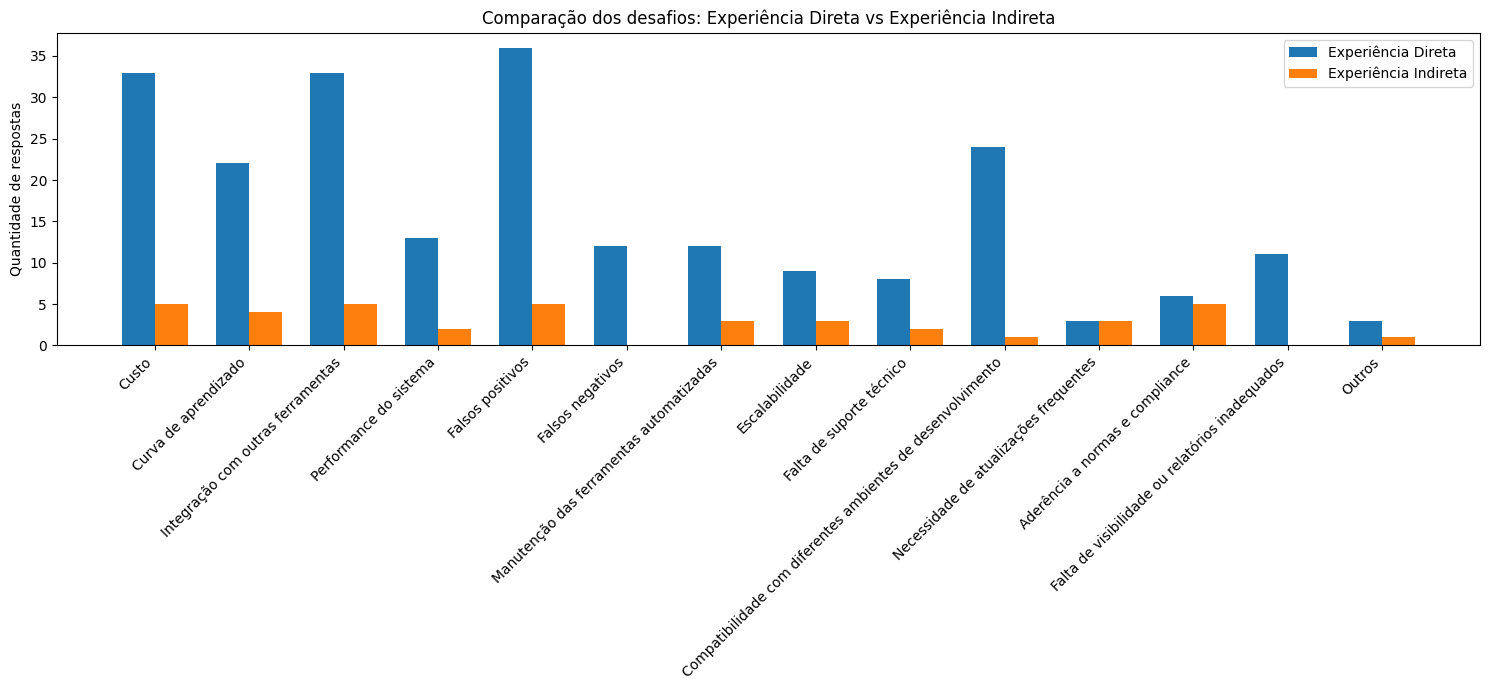

In [ ]:
def grafico_comparacao(df1, df2, nome1, nome2):
    plt.figure(figsize=(15, 7))

    x = np.arange(len(df1.index))
    largura = 0.35

    plt.bar(x - largura/2, df1["Total"], width=largura, label=nome1)
    plt.bar(x + largura/2, df2["Total"], width=largura, label=nome2)

    plt.xticks(x, df1.index, rotation=45, ha='right')
    plt.ylabel("Quantidade de respostas")
    plt.title(f"Comparação dos desafios: {nome1} vs {nome2}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Direta vs Indireta
grafico_comparacao(df_diretas, df_indiretas, "Experiência Direta", "Experiência Indireta")


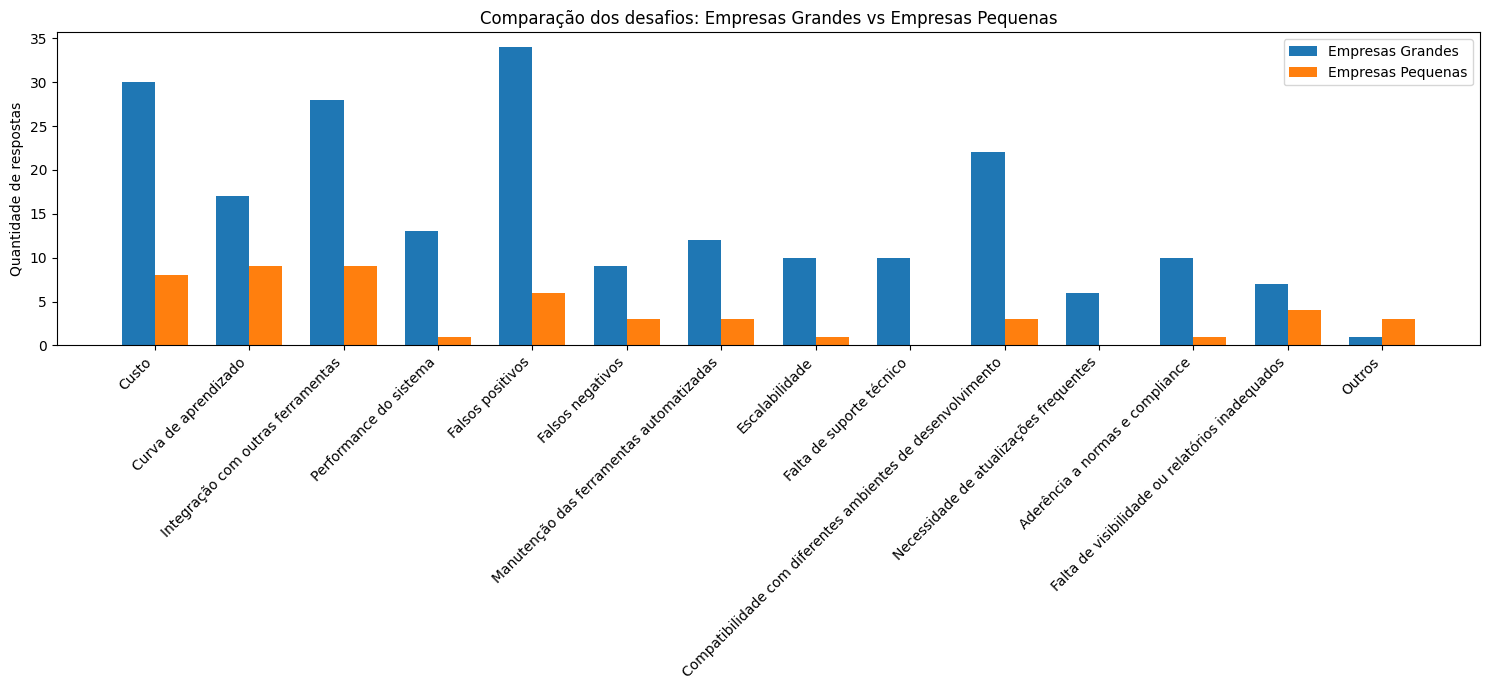

In [ ]:
grafico_comparacao(df_grandes, df_pequenas, "Empresas Grandes", "Empresas Pequenas")


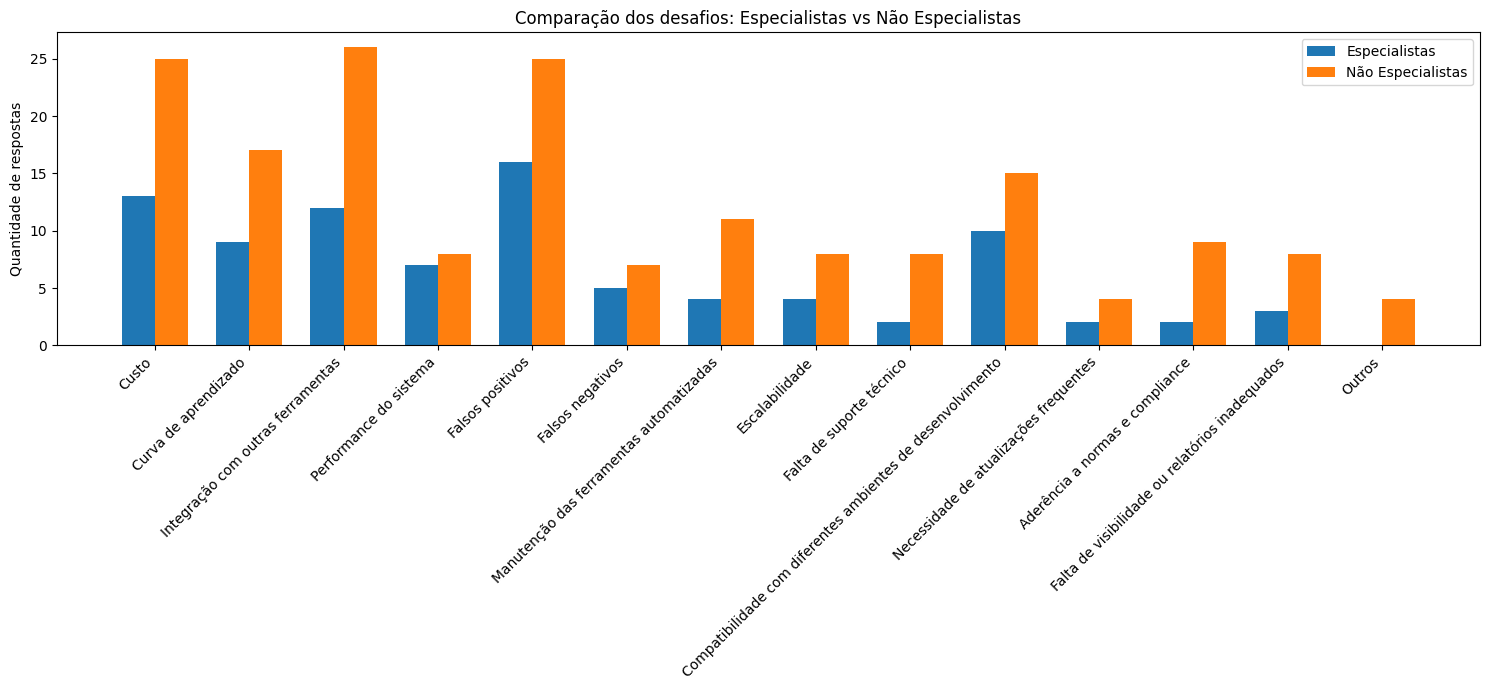

In [ ]:
grafico_comparacao(df_especialistas, df_nao_especialistas, "Especialistas", "Não Especialistas")


In [ ]:
df[col_desafios] = df[col_desafios].fillna("")

# ================================
# 3) TRANSFORMAR MULTIPLAS ESCOLHAS EM LISTA
# ================================
df["desafios_lista"] = df[col_desafios].apply(
    lambda x: [d.strip() for d in str(x).split(",") if d.strip() != ""]
)

# ================================
# 4) DEFINIÇÃO DOS GRUPOS
# ================================
resposta_pequena = ["Até 9 funcionários", "De 10 a 49 funcionários", "De 50 a 99 funcionários"]
resposta_grande  = ["De 100 a 499 funcionários", "De 500 a 999 funcionários", "Mais de 1000 funcionários"]

df["grupo_experiencia"] = df[coluna_experiencia].map({1: "Direta", 0: "Indireta"})
df["grupo_tamanho"] = df[coluna_tamanhoempresa].apply(
    lambda x: "Grande" if x in resposta_grande else ("Pequena" if x in resposta_pequena else np.nan)
)
df["grupo_especialista"] = df[coluna_especialistas].map({1: "Especialista", 0: "Não especialista"})

In [ ]:
df_bruto = df[['grupo_experiencia', 'grupo_tamanho', 'grupo_especialista', 'desafios_lista']]

In [ ]:
import pandas as pd
import plotly.graph_objects as go

import pandas as pd
import plotly.graph_objects as go

cores_fixas = {
    "Especialista": "rgba(187, 119, 230, 0.8)",
    "Não especialista": "rgba(255, 127, 14, 0.5)",
    "Direta": "rgba(152, 26, 230, 0.8)",
    "Indireta": "rgba(214, 39, 40, 0.5)",
    "Grande": "rgba(148, 103, 189, 0.5)",
    "Pequena": "rgba(140, 86, 75, 0.5)"
}

def gerar_sankey_com_listas(df, cols_lineares, col_lista, titulo):
    # 1. Explodir a lista
    df_exp = df.explode(col_lista).dropna(subset=col_lista)

    # 2. Gerar transições das colunas lineares
    linhas_links = []
    for i in range(len(cols_lineares) - 1):
        colA = cols_lineares[i]
        colB = cols_lineares[i + 1]

        parte = (
            df_exp.groupby([colA, colB])
                  .size()
                  .reset_index(name="value")
        )
        parte["source"] = colA
        parte["target"] = colB
        linhas_links.append(parte)

    # 2b. Tamanho → desafios_lista
    parte_final = (
        df_exp.groupby([cols_lineares[-1], col_lista])
              .size()
              .reset_index(name="value")
    )
    parte_final["source"] = cols_lineares[-1]
    parte_final["target"] = col_lista
    linhas_links.append(parte_final)

    # Juntar tudo
    links_df = pd.concat(linhas_links, ignore_index=True)

    # 3. Criar nodes
    labels = pd.concat([
        links_df[cols_lineares[0]],
        links_df[cols_lineares[1]],
        links_df[cols_lineares[2]],
        links_df[col_lista]
    ]).unique().tolist()

    label_to_id = {label: i for i, label in enumerate(labels)}

    # 4. Listas de source/target/value + cores
    source_ids = []
    target_ids = []
    values = []
    link_colors = []

    for _, row in links_df.iterrows():
        src_label = row[row["source"]]
        tgt_label = row[row["target"]]

        source_ids.append(label_to_id[src_label])
        target_ids.append(label_to_id[tgt_label])
        values.append(row["value"])

        # cor vem do nó de origem, quando existente
        if src_label in cores_fixas:
            link_colors.append(cores_fixas[src_label])
        else:
            # se for desafio (camada final), usa uma cor neutra opcional
            link_colors.append("rgba(160, 160, 160, 0.4)")

    # 5. Plot
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels
        ),
        link=dict(
            source=source_ids,
            target=target_ids,
            value=values,
            color=link_colors
        )
    )])

    fig.update_layout(title_text=titulo, font_size=13)
    fig.show()

gerar_sankey_com_listas(
    df_bruto,
    cols_lineares=['grupo_especialista', 'grupo_tamanho', 'grupo_experiencia'],
    col_lista="desafios_lista",
    titulo="Fluxo completo Perfil → Experiência → Tamanho → Desafios"
)

In [ ]:
cores_fixas = {
    "Especialista": "rgba(187, 119, 230, 0.8)",
    "Não especialista": "rgba(255, 127, 14, 0.5)",
    "Direta": "rgba(152, 26, 230, 0.8)",
    "Indireta": "rgba(214, 39, 40, 0.5)",
    "Grande": "rgba(148, 103, 189, 0.5)",
    "Pequena": "rgba(140, 86, 75, 0.5)"
}

def gerar_sankey_colorido(df, coluna_grupo, titulo):

    linhas = []
    for idx, row in df.iterrows():
        grupo = row[coluna_grupo]
        for desafio in row["desafios_lista"]:
            linhas.append((grupo, desafio))
    dados = pd.DataFrame(linhas, columns=["grupo", "desafio"]).dropna()

    display(dados)
    # AGRUPAR para evitar duplicatas (ESSENCIAL!)
    dados_agg = dados.groupby(["grupo", "desafio"]).size().reset_index(name="value")

    labels = list(pd.concat([dados_agg["grupo"], dados_agg["desafio"]]).unique())
    label_to_id = {label: i for i, label in enumerate(labels)}

    source, target, value, link_colors = [], [], [], []

    for idx, row in dados_agg.iterrows():
        source.append(label_to_id[row["grupo"]])
        target.append(label_to_id[row["desafio"]])
        value.append(row["value"])
        link_colors.append(cores_fixas[row["grupo"]])

    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=20,
            thickness=25,
            line=dict(color="black", width=0.7),
            label=labels,
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color=link_colors
        )
    )])

    fig.update_layout(title_text=titulo, font_size=14)
    fig.show()


In [ ]:
gerar_sankey_colorido(df, "grupo_especialista", "Sankey – Especialistas vs Não Especialistas")


,grupo,desafio
0,Não especialista,Falsos positivos
1,Não especialista,Aderência a normas e compliance
2,Especialista,Integração com outras ferramentas
3,Especialista,Falsos positivos
4,Especialista,Aderência a normas e compliance
5,Não especialista,Falsos positivos
6,Não especialista,Falsos negativos
7,Especialista,Integração com outras ferramentas
8,Especialista,Performance do sistema
9,Especialista,Falsos positivos


In [ ]:
gerar_sankey_colorido(df, "grupo_experiencia", "Sankey – Experiência Direta vs Indireta")


In [ ]:
gerar_sankey_colorido(df, "grupo_tamanho", "Sankey – Empresa Grande vs Pequena")


**Q29**

In [ ]:
col_melhorias = 'Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam)'

In [ ]:
melhorias = [
    'Aumentar a abrangência das ameaças',
    'Menos falsos positivos',
    'Melhor integração com o CI/CD',
    'Melhor documentação e suporte',
    'Facilidade de uso',
    'Melhor usabilidade da interface',
    'Redução do tempo de análise',
    'Melhor compatibilidade com diferentes ambientes de desenvolvimento',
    'Relatórios mais detalhados e customizáveis'
]

In [ ]:
col = df[col_melhorias].dropna()

In [ ]:
respostas_explodidas = (
    col.str.split(',')
       .explode()
       .str.strip()
)

In [ ]:
contagem = respostas_explodidas.value_counts()
print(respostas_explodidas.unique())

['Menos falsos positivos' 'Melhor integração com o CI/CD'
 'Melhor compatibilidade com diferentes ambientes de desenvolvimento'
 'Facilidade de uso' 'Melhor documentação e suporte'
 'Redução do tempo de análise' 'Melhor usabilidade da interface'
 'Aumentar a abrangência das ameaças'
 'Relatórios mais detalhados e customizáveis'
 'Feedback e aprendizado contínuo' 'Redução no custo' 'nao posso opninar'
 'Formatação de findings em padrão estipulado como o SARIF.'
 'Customizar regras' 'Classificação e Priorização baseado em Risco'
 'Funil de Classificação.']


In [ ]:
tabela = contagem.reset_index()
tabela.columns = ["Resposta", "Frequência"]

print("\n=== TABELA DE FREQUÊNCIA DAS RESPOSTAS ===\n")
print(tabela)


=== TABELA DE FREQUÊNCIA DAS RESPOSTAS ===

                                             Resposta  Frequência
0                              Menos falsos positivos          48
1                       Melhor integração com o CI/CD          41
2   Melhor compatibilidade com diferentes ambiente...          27
3                       Melhor documentação e suporte          26
4                                   Facilidade de uso          23
5                  Aumentar a abrangência das ameaças          21
6                         Redução do tempo de análise          20
7          Relatórios mais detalhados e customizáveis          18
8                     Melhor usabilidade da interface          13
9                     Feedback e aprendizado contínuo           1
10                                   Redução no custo           1
11                                  nao posso opninar           1
12  Formatação de findings em padrão estipulado co...           1
13                             

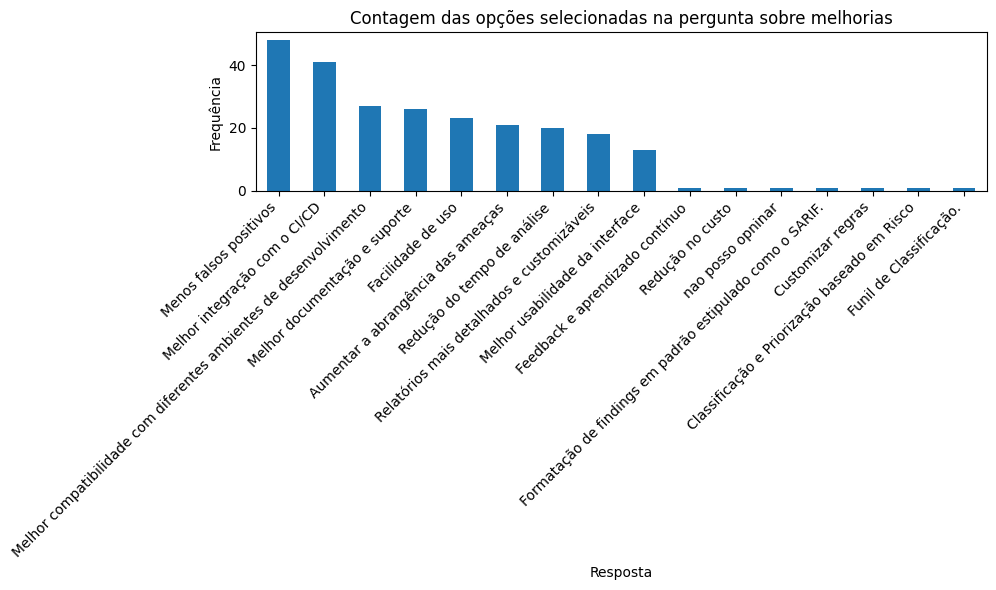

In [ ]:
plt.figure(figsize=(10, 6))
contagem.plot(kind='bar')
plt.xlabel("Resposta")
plt.ylabel("Frequência")
plt.title("Contagem das opções selecionadas na pergunta sobre melhorias")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Q32**

In [ ]:
col_futuro = 'Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?'

In [ ]:
opcoes_validas = ['Sim', 'Não', 'Talvez']

In [ ]:
respostas = (
    df[col_futuro]
    .dropna()
    .astype(str)
    .str.strip()
)


In [ ]:
df = df[df[col_futuro].isin(opcoes_validas)]

In [ ]:
def contar_ferramentas_por_grupo(df, grupo_resposta):
    """ Retorna a contagem de ferramentas para quem respondeu Sim/Não/Talvez """

    subset = df[df[col_futuro] == grupo_resposta][col_fer_futuro].dropna()

    # Explode lista de respostas
    respostas = (
        subset.str.split(',')
              .explode()
              .str.strip()
    )

    # Contagem incluindo ferramentas fora da lista oficial
    return respostas.value_counts()

In [ ]:
contagem = respostas.value_counts().reindex(opcoes_validas, fill_value=0)

In [ ]:
tabela = contagem.reset_index()
tabela.columns = ["Resposta", "Frequência"]

print("\n=== TABELA DE FREQUÊNCIA DAS RESPOSTAS ===\n")
print(tabela)


=== TABELA DE FREQUÊNCIA DAS RESPOSTAS ===

  Resposta  Frequência
0      Sim           6
1      Não           2
2   Talvez           6


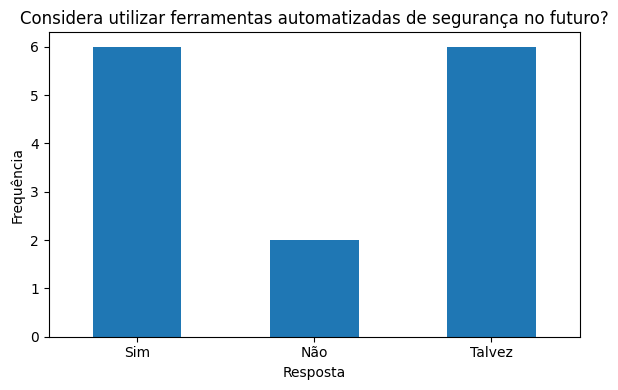

In [ ]:
plt.figure(figsize=(6, 4))
contagem.plot(kind='bar')
plt.xlabel("Resposta")
plt.ylabel("Frequência")
plt.title("Considera utilizar ferramentas automatizadas de segurança no futuro?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Q33**

In [ ]:
col_fer_futuro = 'Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".'

In [ ]:
opcoes_fer_futuro = [
    'Nenhuma', 'Dependabot', 'PHP Security Checker', 'Snyk', 'Clair', 'Blackduck', 'Retire.JS', 'SRC:CLR', 'Anchore', 'Node Security Platform',
    'Trivy', 'Sonatype', 'Whitesource', 'CodeQL', 'CheckStyle', 'Coverity', 'SonarQube', 'Bandit', 'PHPStan', 'LGTM',
    'Brakeman', 'Qark', 'ESLint Security', 'Dart Analyzer', 'Checkmarx', 'DevSkim', 'CFN NAG', 'SpotBugs', 'Chef', 'Ansible',
    'Terraform', 'Puppet', 'Phan', 'Seccomp', 'CloudCustodian', 'Turbot', 'Bane', 'Ansible-Lint', 'Blackbox', 'Puppet-Lint',
    'InSpec', 'Kube Audit', 'Foodcritic', 'Cookstyle', 'conftest', 'Pinterest Knox', 'GitLeaks', 'CyberArk Conjur', 'ThoughtWorks Talisman', 'Berglas',
    'Docker Secrets', 'Trufflehog', 'AppScan', 'Fortify'

]

print(len(opcoes_fer_futuro))

54


In [ ]:
col_f = df[col_fer_futuro].dropna()

In [ ]:
respostas_explodidas = (
    col_f.str.split(',')
       .explode()
       .str.strip()
)

In [ ]:
contagem = respostas_explodidas.value_counts()

In [ ]:
tabela = contagem.reset_index()
tabela.columns = ["Ferramenta", "Frequência"]

print("\n=== TABELA DE FREQUÊNCIA DAS FERRAMENTAS FUTURAS ===\n")
print(tabela)


=== TABELA DE FREQUÊNCIA DAS FERRAMENTAS FUTURAS ===

                                     Ferramenta  Frequência
0                                     Retire.JS           4
1                                     SonarQube           4
2                                      Blackbox           4
3                                      GitLeaks           4
4                                CloudCustodian           4
5                          PHP Security Checker           3
6                                       AppScan           3
7                                     Terraform           3
8                                Docker Secrets           3
9                                       Ansible           3
10                                      Nenhuma           3
11                       Node Security Platform           2
12                                       CodeQL           2
13                              CyberArk Conjur           2
14                                      Forti

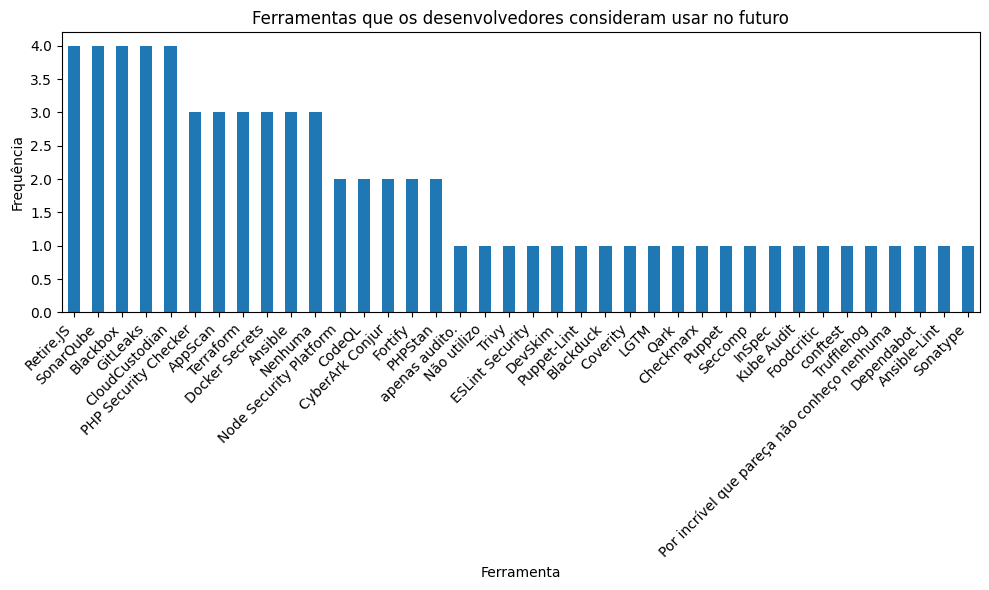

In [ ]:
plt.figure(figsize=(10, 6))
contagem.plot(kind='bar')
plt.xlabel("Ferramenta")
plt.ylabel("Frequência")
plt.title("Ferramentas que os desenvolvedores consideram usar no futuro")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
df[col_futuro] = (
    df[col_futuro]
      .astype(str)
      .str.strip()
      .str.capitalize()
)

# Mantém apenas respostas válidas
df = df[df[col_futuro].isin(opcoes_validas)]


# -----------------------------
# FUNÇÃO PARA CONTAGEM
# -----------------------------

def contar_ferramentas_por_grupo(df, grupo_resposta):
    # Filtra os participantes daquele grupo
    subset = df[df[col_futuro] == grupo_resposta][col_fer_futuro].dropna()

    # Corrige múltiplos separadores
    subset = subset.str.replace("; ", ",").str.replace(";", ",")

    # Explode corretamente
    respostas = (
        subset
        .astype(str)
        .str.split(",")      # separa por vírgula
        .explode()           # transforma lista em linhas
        .str.strip()         # remove espaços
        .replace("", pd.NA)  # remove itens vazios
        .dropna()
    )

    # Agora conta TUDO sem filtrar por opcoes_fer_futuro
    return respostas.value_counts()


# -----------------------------
# CONTAGEM POR GRUPO
# -----------------------------

contagem_sim = contar_ferramentas_por_grupo(df, "Sim")
contagem_nao = contar_ferramentas_por_grupo(df, "Não")
contagem_talvez = contar_ferramentas_por_grupo(df, "Talvez")


# -----------------------------
# EXIBIÇÃO DAS TABELAS
# -----------------------------

print("\n=== Ferramentas citadas por quem respondeu 'Sim' ===\n")
print(contagem_sim.reset_index().rename(columns={'index':'Ferramenta', 'count':'Frequência'}))

print("\n=== Ferramentas citadas por quem respondeu 'Não' ===\n")
print(contagem_nao.reset_index().rename(columns={'index':'Ferramenta', 'count':'Frequência'}))

print("\n=== Ferramentas citadas por quem respondeu 'Talvez' ===\n")
print(contagem_talvez.reset_index().rename(columns={'index':'Ferramenta', 'count':'Frequência'}))


=== Ferramentas citadas por quem respondeu 'Sim' ===

   Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".  \
0                                PHP Security Checker                                                                                               
1                                           Retire.JS                                                                                               
2                                      Docker Secrets                                                                                               
3                                            GitLeaks                                                                                               
4                                      CloudCustodian                                                                                               
5                                           Terrafo

In [ ]:
df[col_fer_futuro].unique()

array(['PHP Security Checker, Retire.JS, SonarQube',
       'Retire.JS, GitLeaks, AppScan', 'SonarQube, Blackbox, AppScan',
       'Não utilizo, apenas audito.',
       'Ansible, Terraform, CloudCustodian, GitLeaks, Docker Secrets',
       'PHP Security Checker, Retire.JS, Node Security Platform, Trivy, CodeQL, PHPStan, ESLint Security, DevSkim, Terraform, CloudCustodian, Puppet-Lint, GitLeaks, CyberArk Conjur, Docker Secrets, Fortify',
       'Nenhuma',
       'PHP Security Checker, Blackduck, Retire.JS, Node Security Platform, CodeQL, Coverity, SonarQube, PHPStan, LGTM, Qark, Checkmarx, Ansible, Terraform, Puppet, Seccomp, CloudCustodian, Blackbox, InSpec, Kube Audit, Foodcritic, conftest, GitLeaks, CyberArk Conjur, Docker Secrets, Trufflehog, AppScan, Fortify',
       'Por incrível que pareça não conheço nenhuma',
       'Dependabot, SonarQube, CloudCustodian, Ansible-Lint, Blackbox',
       'Sonatype, Blackbox', 'Ansible'], dtype=object)